# Machine Learning Homework - Group 22
## Notebook 04 - Model & Assessment  (4 pts)

**Objective.** Train a simple, interpretable binary classifier, assess it properly, and produce
the Kaggle submission. **Kaggle scores this competition on F1**, so F1 is the quantity that is
optimised, reported and tuned for.

**Inputs.** `data/train_clean.csv`, `data/test_clean.csv` (Notebook 02), `data/selected_columns.csv`
(Notebook 03), `data/train_raw.csv` (only to recover `purchase_date` for a chronological check),
`data/sample_submission.csv` (the submission contract)
**Outputs.** `deliverables/ML_Group_22_Version01.csv` (the course names submissions `<team>_Version<NN>.csv`; this is the first), `artifacts/metrics/*` (assessment,
protocol comparison, scaling check, model comparison, threshold curves, holdout by customer type),
`artifacts/figures/nb04_assessment.png`

### What the earlier notebooks force us to do here

| Earlier finding | Consequence for modelling |
|---|---|
| NB01: the same `customer_id` appears in many rows | A random split can put the same customer in train and validation and inflate the score. Model selection therefore uses **`GroupKFold` on `customer_id`** |
| NB01: train is 2015-2025, test is 2025-2026, and test customers are systematically longer-tenured | A random-CV number is optimistic for the leaderboard, so a **chronological** estimate (`TimeSeriesSplit`) is also reported as the realistic expectation |
| NB01: classes are close to balanced (44/56), not imbalanced | No resampling (also forbidden); `class_weight` is still searched because shifting the boundary is exactly what F1 rewards |
| NB02: sentinels and structural nulls became NaN + flags | Those flags are ordinary candidate features now; nothing is re-preprocessed here |
| NB03: the selected set of concepts / columns, chosen by measured CV F1 | The selected set is used, and the full set is scored alongside it so the selection stays auditable |
| NB02: only the **numeric** columns were standardised, the 0/1 flags and dummies were left at 0/1 | Re-standardising the whole matrix inside every fold divides a rare dummy by a standard deviation of about 0.07 and hands it an unearned weight. Cell 5 measures both options; the model consumes Notebook 02's matrix as delivered |
| NB01 and cell 2: the test window lies entirely after the train window, and almost all test rows belong to a customer already seen in train | `GroupKFold` is the right way to *choose* a model but it is pessimistic about the submission, because it never lets a scored row have a history. The chronological holdout in cell 8 separates returning from new customers so the expectation is grounded in a measurement |

### Why tuning the threshold is the main F1 lever left
F1 is not maximised at probability 0.5 unless the classes are balanced and the model is
calibrated. The threshold is therefore chosen **for F1** using `precision_recall_curve` on
out-of-fold probabilities. To avoid fooling ourselves it is selected inside an inner split and
evaluated on an outer split, so the reported tuned F1 never saw its own threshold. This is the
one step that goes slightly beyond what was coded in class; it is built entirely from taught
functions and is justified here because the competition metric is F1.

### Models considered
Only models taught in the course: a `DummyClassifier` baseline, `LogisticRegression` (searched
over `C` and `class_weight`), `DecisionTreeClassifier` (`max_depth`, `min_samples_leaf`) and
`PCA` + `LogisticRegression`. Gradient boosting, random forests, kNN, SVM and neural networks are
outside the toolkit and are not used.

### Why Notebook 04 may use a different feature set than Notebook 03
Notebook 03 chose its 64-column set with a parsimony rule under **random** cross-validation, where
the selected and full sets were indistinguishable. Under the stricter `GroupKFold` protocol used
here the two separate, and the full set wins (see Cell 5). That is not a contradiction: the
selected set is the economical choice, while a logistic model with heavy regularisation copes with
collinear columns by shrinking them instead of needing them deleted. Both sets are scored, the
numbers are printed, and the better one under the strict protocol is used, so the choice stays
auditable rather than a silent override.

### Order of operations
1. Setup
2. Load the outputs of Notebooks 02 and 03 and verify them
3. Build the candidate feature sets
4. Choose the validation protocol, and measure what a random split would hide
5. Select the model with `GridSearchCV` under the strict protocol
6. Tune the F1 decision threshold with nested validation
7. Fit the final model on all training rows and read it out
8. Assess: confusion matrix, PR curve, ROC curve, F1-vs-threshold curve
9. Predict the test set and validate the submission contract
10. Persist metrics and summarise

### Cell 1 - Environment
**Purpose.** Import the modelling and assessment tools, all from the taught set.
**Look at.** `GroupKFold`, `TimeSeriesSplit` and `GridSearchCV` are the three that carry the decisions
made later.

In [1]:
# CELL 1 - Setup: imports, paths, constants.
import json
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
from pathlib import Path
from sklearn.base import clone
from sklearn.dummy import DummyClassifier
from sklearn.linear_model import LogisticRegression
from sklearn.tree import DecisionTreeClassifier
from sklearn.decomposition import PCA
from sklearn.preprocessing import StandardScaler
from sklearn.pipeline import Pipeline
from sklearn.model_selection import (StratifiedKFold, GroupKFold, TimeSeriesSplit,
                                     GridSearchCV, cross_validate)
from sklearn.metrics import (f1_score, accuracy_score,
                             roc_auc_score, confusion_matrix, classification_report,
                             precision_recall_curve, roc_curve, get_scorer)

ROOT = Path.cwd().parent
DATA_DIR = ROOT / "data"
FIG_DIR = ROOT / "artifacts" / "figures"
MET_DIR = ROOT / "artifacts" / "metrics"
DELIV_DIR = ROOT / "deliverables"

TARGET = "repeat_purchase_90d"
RANDOM_STATE = 42

# Course rule: every Kaggle submission must be named <team>_Version<NN>.csv, and the file that is
# finally selected has to be the one the notebook produces. This is the group's first submission, so
# Version01 - bump SUBMISSION_VERSION for each later upload and the notebook writes the new name.
TEAM = "ML_Group_22"
SUBMISSION_VERSION = "Version01"
SUBMISSION_FILE = "{}_{}.csv".format(TEAM, SUBMISSION_VERSION)
PLOT_BLUE = "#1779A8"
PLOT_ORANGE = "#C96A00"
ID_COLS = ["ID", "customer_id"]

def guide(ax, text):
    # Append a "how to read" caption to the axes title, so a figure still explains itself
    # when it is printed on a page or opened on its own.
    ax.set_title(ax.get_title() + "\n" + text, fontsize=8)

sns.set_theme(style="whitegrid")
print("Environment ready.")
print("  submission goes to:", DELIV_DIR)

Environment ready.
  submission goes to: C:\Users\Mohamed_Triki\Desktop\Projets\machine_learning\ML_Group_22\deliverables


### Cell 2 - Load and verify
**Purpose.** Read Notebook 02's matrices, Notebook 03's selection, and the raw dates needed for a
chronological check.
**Method.** Rows are re-ordered chronologically so `TimeSeriesSplit` means what it says, and the test
IDs are asserted against the submission template.
**Look at.** `test IDs match the submission template: True` - the contract is checked before any
modelling, not at the end. And the share of test rows belonging to a customer already seen in train,
which is what makes the population of the leaderboard different from a grouped validation fold.

In [2]:
# CELL 2 - Load the outputs of Notebooks 02 and 03 and verify them.
train = pd.read_csv(DATA_DIR / "train_clean.csv")
test = pd.read_csv(DATA_DIR / "test_clean.csv")
sel_cols = pd.read_csv(DATA_DIR / "selected_columns.csv")
lists = pd.read_csv(DATA_DIR / "feature_lists.csv")
raw = pd.read_csv(DATA_DIR / "train_raw.csv")
sample_sub = pd.read_csv(DATA_DIR / "sample_submission.csv")

# purchase_date lives in the raw frame; re-attach it on ID (never .merge) so the rows can be
# ordered chronologically for the TimeSeriesSplit protocol.
dates = raw[["ID", "purchase_date"]].set_index("ID")
train = train.set_index("ID").join(dates).reset_index().sort_values("purchase_date").reset_index(drop=True)

y = train[TARGET].to_numpy()
groups = train["customer_id"].to_numpy()

all_features = lists[lists["kind"].isin(["numeric_scaled", "indicator_flag", "one_hot"])]["feature"].tolist()
selected = sel_cols["column"].tolist()
group_lookup = dict(zip(sel_cols["column"], sel_cols["group"]))

print("=== Loaded ===")
print("  train:", train.shape, "| test:", test.shape)
print("  rows ordered chronologically:", train["purchase_date"].min(), "->", train["purchase_date"].max())
print("  features selected by NB03:", len(selected), "| all NB02 features:", len(all_features))
print("  unique customers:", int(train["customer_id"].nunique()),
      "| max rows per customer:", int(train["customer_id"].value_counts().max()))
print("\n=== Checks ===")
print("  selected set is a subset of all features:", all(c in set(all_features) for c in selected))
print("  no nulls in the modelling columns       :", bool(train[selected].isna().sum().sum() == 0))
print("  test IDs match the submission template  :", list(test["ID"]) == list(sample_sub["ID"]))
train_customers = set(train["customer_id"])
returning = [c in train_customers for c in test["customer_id"]]
given = [f for f in all_features + selected if f in ("ID", "customer_id")]
print("  identifiers reaching the model          :", given if given else "none - ID and customer_id are kind=identifier")
assert not given, "the customer key must never become a model feature"
print("  test rows whose customer is in train    : {:,} of {:,} = {:.1f}%  (a returning customer is".format(
    int(sum(returning)), len(test), 100.0 * sum(returning) / len(test)))
print("                                            the design of this dataset, not a leak - see cell 4)")
assert all(c in set(all_features) for c in selected)
assert list(test["ID"]) == list(sample_sub["ID"]), "the submission must keep the template IDs in order"

=== Loaded ===
  train: (6469, 128) | test: (986, 126)
  rows ordered chronologically: 2015-07-11 -> 2025-02-15
  features selected by NB03: 64 | all NB02 features: 124
  unique customers: 607 | max rows per customer: 276

=== Checks ===
  selected set is a subset of all features: True
  no nulls in the modelling columns       : True
  test IDs match the submission template  : True
  identifiers reaching the model          : none - ID and customer_id are kind=identifier
  test rows whose customer is in train    : 932 of 986 = 94.5%  (a returning customer is
                                            the design of this dataset, not a leak - see cell 4)


### Cell 3 - Candidate feature sets
**Purpose.** Keep both the selected set and the full set in play.
**Look at.** The two counts; whichever wins under the strict protocol is used, and the reason is
reported rather than assumed.

In [3]:
# CELL 3 - The two feature sets that will be compared.
feature_sets = {"NB03 selected": selected, "NB02 all features": all_features}
X_sets = {name: train[cols].to_numpy() for name, cols in feature_sets.items()}
X_test_sets = {name: test[cols].to_numpy() for name, cols in feature_sets.items()}

print("=== Candidate feature sets ===")
for name, cols in feature_sets.items():
    print("  {:18s} {:4d} columns".format(name, len(cols)))
print("\n  matrices come straight from train_clean.csv: no re-imputation, re-scaling or re-encoding")

=== Candidate feature sets ===


  NB03 selected        64 columns
  NB02 all features   124 columns

  matrices come straight from train_clean.csv: no re-imputation, re-scaling or re-encoding


### Cell 4 - Validation protocol
**Purpose.** Decide how the model is validated, and prove that the choice actually isolates customers.
**Method.** The same reference model scored by random stratified folds, by customer groups and in time
order; then, for each protocol, a count of the customers and rows that sit on **both** sides of the
split. The matrix enters unmodified - Notebook 02's scaler was fitted on training rows only, and
cell 5 measures whether re-scaling inside the fold would be better or worse.
**Look at.** Two things: the spread between the three F1 numbers, which is the price of the optimism
Notebook 01 warned about; and the audit column, where `GroupKFold` must be the only protocol with
nothing on both sides. The chronological and random splits are *not* bugs - a returning customer's
past legitimately belongs in the past, which is exactly the condition of the test file.

In [4]:
# CELL 4 - Choose the validation protocol, and prove that it isolates customers.
# One reference model, scored three ways. GroupKFold on customer_id is the strict choice because
# NB01 showed customers repeat across rows; the chronological split is the realistic choice
# because NB01 showed the test set is a later period than train.
# The data is used exactly as Notebook 02 delivered it: numeric columns standardised on the
# training rows, 0/1 flags and dummies left at 0/1. Cell 5 measures the alternative.
ref = LogisticRegression(max_iter=5000, random_state=RANDOM_STATE)
X_sel = X_sets["NB03 selected"]

protocols = {
    "StratifiedKFold (random)": StratifiedKFold(n_splits=5, shuffle=True, random_state=RANDOM_STATE),
    "GroupKFold (customer_id)": GroupKFold(n_splits=5),
    "TimeSeriesSplit (chronological)": TimeSeriesSplit(n_splits=5),
}

prot_rows = []
for name, splitter in protocols.items():
    # groups means something to GroupKFold and nothing to the other two, and sklearn warns about
    # the difference - so it is passed only where it is used.
    if name.startswith("GroupKFold"):
        res = cross_validate(ref, X_sel, y, cv=splitter, scoring=get_scorer("f1"), groups=groups)
    else:
        res = cross_validate(ref, X_sel, y, cv=splitter, scoring=get_scorer("f1"))
    prot_rows.append({"protocol": name, "cv_f1_mean": float(res["test_score"].mean()),
                      "cv_f1_std": float(res["test_score"].std()),
                      "min_fold": float(res["test_score"].min()),
                      "max_fold": float(res["test_score"].max())})
prot = pd.DataFrame(prot_rows)
print("=== Same model, three validation protocols ===")
print(prot.to_string(index=False, float_format=lambda v: "{:.4f}".format(v)))
print("\n  spread between protocols: {:.4f} F1".format(prot["cv_f1_mean"].max() - prot["cv_f1_mean"].min()))
print("  -> model selection uses GroupKFold: customer repetition is the concrete leakage risk")
print("  -> the chronological number is kept as the realistic leaderboard expectation")

# Contamination audit. For every protocol: how many validation customers, and how many validation
# rows, belong to a customer who is also in the fitting part of that same split.
print("\n=== Audit: can a customer be on both sides of the split? ===")
audit_rows = []
for name, splitter in protocols.items():
    span_customers, known_rows, fold_rows = [], [], []
    fold_iter = splitter.split(X_sel, y, groups) if name.startswith("GroupKFold") else splitter.split(X_sel, y)
    for tr_idx, va_idx in fold_iter:
        in_fit = set(groups[tr_idx])
        is_returning = [c in in_fit for c in groups[va_idx]]
        span_customers.append(len([c for c in set(groups[va_idx]) if c in in_fit]))
        known_rows.append(int(sum(is_returning)))
        fold_rows.append(len(va_idx))
    audit_rows.append({"protocol": name, "max_customers_on_both_sides": int(max(span_customers)),
                       "validation_rows_with_a_known_customer": int(sum(known_rows)),
                       "share_of_validation_rows": round(float(np.mean(
                           [a / b for a, b in zip(known_rows, fold_rows)])), 4)})
audit = pd.DataFrame(audit_rows)


def audit_value(prefix, column):
    # Read one cell of the audit by protocol name, so nothing depends on dict order.
    return audit[audit['protocol'].str.startswith(prefix)][column].tolist()[0]
print(audit.to_string(index=False))
assert int(audit_value("GroupKFold", "max_customers_on_both_sides")) == 0, \
    "GroupKFold must keep every customer entirely inside one fold"
assert int(audit_value("GroupKFold", "validation_rows_with_a_known_customer")) == 0
print("\n  -> GroupKFold(5) on customer_id: 0 customers and 0 rows ever appear on both sides, so no")
print("     transaction of a validation customer is used to fit the model that scores it. A random")
print("     split puts a returning customer on {:.0f}% of the validation rows, and the chronological".format(
    100 * float(audit_value("StratifiedKFold", "share_of_validation_rows"))))
print("     split on {:.0f}% - legitimate there, because the fitting part is genuinely their past,".format(
    100 * float(audit_value("TimeSeriesSplit", "share_of_validation_rows"))))
print("     and it is the condition of the test file ({:.1f}% of its rows are returning customers).".format(
    100.0 * sum(returning) / len(test)))
STRICT = GroupKFold(n_splits=5)

=== Same model, three validation protocols ===
                       protocol  cv_f1_mean  cv_f1_std  min_fold  max_fold
       StratifiedKFold (random)      0.7447     0.0125    0.7283    0.7643
       GroupKFold (customer_id)      0.7389     0.0125    0.7227    0.7546
TimeSeriesSplit (chronological)      0.7414     0.0191    0.7186    0.7632

  spread between protocols: 0.0057 F1
  -> model selection uses GroupKFold: customer repetition is the concrete leakage risk
  -> the chronological number is kept as the realistic leaderboard expectation

=== Audit: can a customer be on both sides of the split? ===
                       protocol  max_customers_on_both_sides  validation_rows_with_a_known_customer  share_of_validation_rows
       StratifiedKFold (random)                          332                                   6271                    0.9694
       GroupKFold (customer_id)                            0                                      0                    0.0000
TimeSeri

### Cell 5 - Scaling check, then model selection
**Purpose.** Settle the one preprocessing question that is still open at this point - whether to
re-standardise the matrix inside every fold - and then choose the model and its feature set by
measured F1.
**Method.** First the scaling comparison: the matrix as Notebook 02 delivered it (numeric columns
standardised on the training rows, 0/1 columns left at 0/1) against re-fitting a `StandardScaler`
inside each fold on **every** column, and on the numeric columns alone. All three are scored with the
same `GroupKFold`, the same fixed `C`, and both F1 and ROC-AUC are reported, because a scaler can
change the ranking without changing the score at 0.50. Then `GridSearchCV` for a dummy baseline,
logistic regression, a decision tree and PCA plus logistic, each on both feature sets.
**Look at.** Whether re-scaling the binary columns helps or hurts, the margin over the dummy baseline,
and whether the selected set beats the full set here.

=== Scaling decision, same folds, same C, both metrics ===


  as Notebook 02 left it (0/1 columns stay 0/1)  CV F1 0.7481   ROC-AUC 0.7899

  re-scale EVERY column inside the fold          CV F1 0.7478   ROC-AUC 0.7865


  re-scale the numeric columns inside the fold   CV F1 0.7470   ROC-AUC 0.7898

  -> the 0/1 columns are left alone: re-scaling them costs ranking quality, and the
     fold-level refit of the numeric columns changes nothing worth its complexity.
     The models below therefore take the Notebook 02 matrix as it is.



=== Every model x feature set, GroupKFold CV, scoring = F1 ===
                model       feature_set  cv_f1_mean                                         best_params
             logistic NB02 all features      0.7484         {'clf__C': 0.03, 'clf__class_weight': None}
       PCA + logistic NB02 all features      0.7445            {'clf__C': 0.1, 'pca__n_components': 40}
             logistic     NB03 selected      0.7406        {'clf__C': 0.003, 'clf__class_weight': None}
       PCA + logistic     NB03 selected      0.7374           {'clf__C': 10.0, 'pca__n_components': 10}
        decision tree     NB03 selected      0.7233 {'clf__max_depth': 8, 'clf__min_samples_leaf': 100}
        decision tree NB02 all features      0.7196 {'clf__max_depth': 8, 'clf__min_samples_leaf': 100}
dummy (most_frequent)     NB03 selected      0.7176                                                  {}
dummy (most_frequent) NB02 all features      0.7176                                                  {}



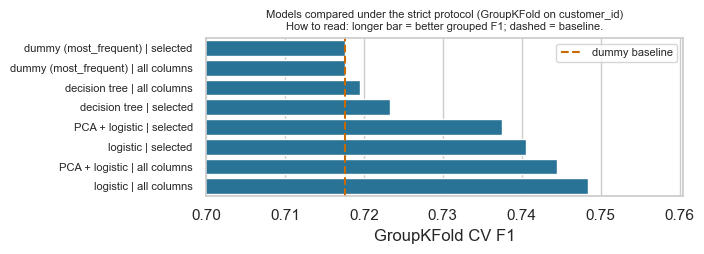

In [5]:
# CELL 5 - First the scaling decision, measured; then model selection with GridSearchCV.
# Why this is checked here: a 0/1 flag or a one-hot dummy that appears on 0.5% of the rows has a
# standard deviation of about 0.07, so standardising it turns a single 1 into a value near 14. Under
# a penalised logistic model that column then escapes most of the penalty, which is a change of
# behaviour, not of appearance. Notebook 02 therefore scales the numeric columns only.
numeric_only = set(lists[lists["kind"] == "numeric_scaled"]["feature"])


def fold_scaled(X_fit, X_score, cols, mode):
    # Return the two fold matrices under a scaling mode: "nb02" (pass through), "numeric"
    # (StandardScaler on the numeric columns only) or "all" (StandardScaler on every column).
    a, b = X_fit.copy(), X_score.copy()
    if mode == "nb02":
        return a, b
    keep = [i for i, c in enumerate(cols)
            if mode == "all" or c in numeric_only]
    sc = StandardScaler()
    a[:, keep] = sc.fit_transform(X_fit[:, keep])
    b[:, keep] = sc.transform(X_score[:, keep])
    return a, b


print("=== Scaling decision, same folds, same C, both metrics ===")
X_probe = X_sets["NB02 all features"]
probe_rows = []
for mode, label in [("nb02", "as Notebook 02 left it (0/1 columns stay 0/1)"),
                    ("all", "re-scale EVERY column inside the fold"),
                    ("numeric", "re-scale the numeric columns inside the fold")]:
    fold_f1, fold_auc = [], []
    for tr_idx, va_idx in STRICT.split(X_probe, y, groups):
        a, b = fold_scaled(X_probe[tr_idx], X_probe[va_idx], all_features, mode)
        m = LogisticRegression(C=0.01, max_iter=5000, random_state=RANDOM_STATE).fit(a, y[tr_idx])
        prob = m.predict_proba(b)[:, 1]
        fold_f1.append(f1_score(y[va_idx], (prob >= 0.5).astype(int)))
        fold_auc.append(roc_auc_score(y[va_idx], prob))
    probe_rows.append({"scaling": label, "cv_f1_mean": float(np.mean(fold_f1)),
                       "roc_auc_mean": float(np.mean(fold_auc))})
    print("  {:46s} CV F1 {:.4f}   ROC-AUC {:.4f}".format(label, np.mean(fold_f1), np.mean(fold_auc)))
scaling_check = pd.DataFrame(probe_rows)
scaling_check.to_csv(MET_DIR / "scaling_check.csv", index=False)
print("\n  -> the 0/1 columns are left alone: re-scaling them costs ranking quality, and the")
print("     fold-level refit of the numeric columns changes nothing worth its complexity.")
print("     The models below therefore take the Notebook 02 matrix as it is.\n")

# Each candidate is a Pipeline so the search has one uniform interface; only the PCA branch adds a
# scaler, because PCA is a variance-based method and needs comparable column scales to make sense.
grids = {
    "dummy (most_frequent)": (Pipeline([("clf", DummyClassifier(strategy="most_frequent"))]), {}),
    "logistic": (Pipeline([("clf", LogisticRegression(max_iter=5000, random_state=RANDOM_STATE))]),
                 {"clf__C": [0.0001, 0.0003, 0.001, 0.003, 0.01, 0.03, 0.1, 0.3, 1.0, 3.0, 10.0],
                  "clf__class_weight": [None, "balanced"]}),
    "decision tree": (Pipeline([("clf", DecisionTreeClassifier(random_state=RANDOM_STATE))]),
                      {"clf__max_depth": [3, 5, 8, None],
                       "clf__min_samples_leaf": [1, 10, 25, 50, 100]}),
    "PCA + logistic": (Pipeline([("scale", StandardScaler()),
                                 ("pca", PCA(random_state=RANDOM_STATE)),
                                 ("clf", LogisticRegression(max_iter=5000, random_state=RANDOM_STATE))]),
                       {"pca__n_components": [5, 10, 20, 40],
                        "clf__C": [0.01, 0.1, 1.0, 10.0]}),
}

searches, rows = {}, []
for name, (pipe, grid) in grids.items():
    for set_name, X in X_sets.items():
        key = (name, set_name)
        search = GridSearchCV(pipe, grid, cv=STRICT, scoring=get_scorer("f1"), error_score=0)
        search.fit(X, y, groups=groups)
        searches[key] = search
        rows.append({"model": name, "feature_set": set_name,
                     "cv_f1_mean": float(search.best_score_),
                     "best_params": str(search.best_params_)})

full_df = pd.DataFrame(rows).sort_values("cv_f1_mean", ascending=False).reset_index(drop=True)
print("=== Every model x feature set, GroupKFold CV, scoring = F1 ===")
print(full_df.to_string(index=False, float_format=lambda v: "{:.4f}".format(v)))

winner = full_df.to_dict("records")[0]
best_search = searches[(winner["model"], winner["feature_set"])]
base_estimator = best_search.best_estimator_
print("\n  selected : {} on [{}]".format(winner["model"], winner["feature_set"]))
print("  params   : {}".format(winner["best_params"]))
print("  CV F1    : {:.4f}".format(winner["cv_f1_mean"]))
print("  margin over the dummy baseline: {:+.4f} F1".format(
    winner["cv_f1_mean"] - float(full_df[full_df["model"].str.startswith("dummy")]["cv_f1_mean"].max())))

# The same table as a picture, so the ranking survives being lifted into the summary PDF.
plot_df = full_df.copy()
short = {"NB02 all features": "all columns", "NB03 selected": "selected"}
plot_df["label"] = plot_df["model"] + " | " + plot_df["feature_set"].map(short)
plot_df = plot_df.sort_values("cv_f1_mean")
fig, ax = plt.subplots(figsize=(7.2, 2.7))            # print width: the PDF places this 1:1
sns.barplot(data=plot_df, y="label", x="cv_f1_mean", color=PLOT_BLUE, ax=ax)
ax.axvline(float(plot_df[plot_df["model"].str.startswith("dummy")]["cv_f1_mean"].max()),
           color=PLOT_ORANGE, linestyle="--", label="dummy baseline")
ax.set_title("Models compared under the strict protocol (GroupKFold on customer_id)")
ax.set_xlabel("GroupKFold CV F1")
ax.set_ylabel("")
ax.set_xlim(0.70, float(plot_df["cv_f1_mean"].max()) + 0.012)
ax.legend(loc="upper right", fontsize=8)
plt.setp(ax.get_yticklabels(), fontsize=8)
guide(ax, "How to read: longer bar = better grouped F1; dashed = baseline.")
plt.tight_layout()
plt.savefig(FIG_DIR / "nb04_model_comparison.png", dpi=200)
plt.show()

### Cell 6 - Threshold tuning, honestly
**Purpose.** Move the decision threshold where F1 is maximised, without fooling ourselves.
**Method.** Nested validation: an inner set of folds picks the threshold from inner out-of-fold
probabilities, the outer fold is then scored with it.
**Look at.** The gain column: if tuning does not survive nesting, it is not a real gain.

In [6]:
# CELL 6 - Tune the decision threshold for F1, and evaluate it honestly.
# Picking a threshold on the same predictions used to report the score is self-deception, so the
# threshold is chosen from INNER out-of-fold probabilities and scored on the OUTER fold.
def f1_curve(target, probs):
    # Precision, recall, thresholds and the F1 at each threshold, from taught functions only.
    precision, recall, thresholds = precision_recall_curve(target, probs)
    with np.errstate(divide="ignore", invalid="ignore"):
        f1s = np.where(precision + recall > 0, 2 * precision * recall / (precision + recall), 0.0)
    return precision, recall, thresholds, f1s[:-1]


def best_threshold(probs, target):
    _, _, thresholds, f1s = f1_curve(target, probs)
    if len(thresholds) == 0:
        return 0.5, 0.0
    k = int(np.argmax(f1s))
    return float(thresholds[k]), float(f1s[k])


X_best = X_sets[winner["feature_set"]]

nested_rows = []
for fold, (tr_idx, va_idx) in enumerate(GroupKFold(n_splits=5).split(X_best, y, groups), start=1):
    inner_X, inner_y, inner_g = X_best[tr_idx], y[tr_idx], groups[tr_idx]
    inner_oof = np.zeros(len(tr_idx))
    for itr, iva in GroupKFold(n_splits=4).split(inner_X, inner_y, inner_g):
        m = clone(base_estimator)
        m.fit(inner_X[itr], inner_y[itr])
        inner_oof[iva] = m.predict_proba(inner_X[iva])[:, 1]
    thr, inner_f1 = best_threshold(inner_oof, inner_y)

    outer_model = clone(base_estimator)
    outer_model.fit(X_best[tr_idx], y[tr_idx])
    outer_probs = outer_model.predict_proba(X_best[va_idx])[:, 1]
    nested_rows.append({"fold": fold, "inner_threshold": thr, "inner_f1": inner_f1,
                        "f1_at_tuned": f1_score(y[va_idx], (outer_probs >= thr).astype(int)),
                        "f1_at_0_50": f1_score(y[va_idx], (outer_probs >= 0.5).astype(int))})

nested = pd.DataFrame(nested_rows)
print("=== Nested threshold tuning (inner chooses, outer evaluates) ===")
print(nested.to_string(index=False, float_format=lambda v: "{:.4f}".format(v)))
print("\n  mean outer F1 at the tuned threshold : {:.4f} (+/- {:.4f})".format(
    nested["f1_at_tuned"].mean(), nested["f1_at_tuned"].std()))
print("  mean outer F1 at the default 0.50      : {:.4f} (+/- {:.4f})".format(
    nested["f1_at_0_50"].mean(), nested["f1_at_0_50"].std()))
print("  measured gain from tuning the threshold: {:+.4f} F1".format(
    nested["f1_at_tuned"].mean() - nested["f1_at_0_50"].mean()))

=== Nested threshold tuning (inner chooses, outer evaluates) ===
 fold  inner_threshold  inner_f1  f1_at_tuned  f1_at_0_50
    1           0.3786    0.7558       0.7716      0.7592
    2           0.3525    0.7564       0.7606      0.7554
    3           0.3565    0.7595       0.7450      0.7511
    4           0.4391    0.7604       0.7399      0.7302
    5           0.4064    0.7655       0.7580      0.7462

  mean outer F1 at the tuned threshold : 0.7550 (+/- 0.0127)
  mean outer F1 at the default 0.50      : 0.7484 (+/- 0.0113)
  measured gain from tuning the threshold: +0.0066 F1


### Cell 7 - Final model and read-out
**Purpose.** Fit on all training rows, fix the threshold, and show what the model learned.
**Method.** Out-of-fold probabilities give the diagnostics and the single threshold applied to test;
a chronological holdout re-tests that threshold on a later window.
**Look at.** The coefficient table and its concept-level aggregation - the model should agree with
Notebook 01's correlations.

In [7]:
# CELL 7 - Fit the final model on all training rows, fix the threshold, and read the model out.
final_model = clone(base_estimator)
final_model.fit(X_best, y)

# Out-of-fold probabilities of the final model: used for the reported diagnostics and for the
# single threshold that will be applied to the test set.
oof = np.zeros(len(y))
for tr_idx, va_idx in GroupKFold(n_splits=5).split(X_best, y, groups):
    m = clone(base_estimator)
    m.fit(X_best[tr_idx], y[tr_idx])
    oof[va_idx] = m.predict_proba(X_best[va_idx])[:, 1]

THRESHOLD, thr_f1 = best_threshold(oof, y)
print("=== Final model ===")
print("  model      :", winner["model"], "on", winner["feature_set"])
print("  params     :", winner["best_params"])
print("  GroupKFold CV F1 : {:.4f}".format(winner["cv_f1_mean"]))
print("\n=== Threshold ===")
print("  chosen for F1 on out-of-fold probabilities : {:.4f}".format(THRESHOLD))
print("  out-of-fold F1 at that threshold           : {:.4f}".format(thr_f1))
print("  out-of-fold F1 at the default 0.50         : {:.4f}".format(
    f1_score(y, (oof >= 0.5).astype(int))))

# The test window is later than the training window, so the threshold is also tested on a purely
# time-ordered split: fit on the earliest 80% of rows, score the latest 20%.
cut = int(0.8 * len(y))
m_ch = clone(base_estimator)
m_ch.fit(X_best[:cut], y[:cut])
p_ch = m_ch.predict_proba(X_best[cut:])[:, 1]
print("\n=== Chronological holdout (fit earliest 80%, score latest 20%) ===")
print("  F1 at the default 0.50     : {:.4f}".format(f1_score(y[cut:], (p_ch >= 0.5).astype(int))))
print("  F1 at the chosen threshold : {:.4f}   (the threshold was picked on grouped folds, not here)".format(
    f1_score(y[cut:], (p_ch >= THRESHOLD).astype(int))))
print("  positive rate in the held-out tail : {:.4f}  vs {:.4f} in the earlier rows".format(
    y[cut:].mean(), y[:cut].mean()))

# Read-out: coefficients for a linear model, importances for a tree.
clf = final_model.named_steps["clf"]
readout_name, readout_col = ("coefficient", "coef") if hasattr(clf, "coef_") else ("importance", "importance")
values = clf.coef_[0] if readout_name == "coefficient" else clf.feature_importances_
readout = pd.DataFrame({"column": feature_sets[winner["feature_set"]],
                        readout_col: np.asarray(values).ravel()})
readout["group"] = [group_lookup.get(c, c) for c in readout["column"]]
readout["abs"] = readout[readout_col].abs()
readout = readout.sort_values("abs", ascending=False).reset_index(drop=True)
print("\n=== Model read-out: {} of every column, largest effect first ===".format(readout_name))
print(readout.to_string(index=False, float_format=lambda v: "{:.4f}".format(v)))

if readout_name == "coefficient":
    grp = readout.groupby("group")["abs"].max().sort_values(ascending=False)
    print("\n=== Same read-out aggregated to the concept level (NB03 groups) ===")
    print(grp.to_frame("max_abs_coef").to_string(float_format=lambda v: "{:.4f}".format(v)))

=== Final model ===
  model      : logistic on NB02 all features
  params     : {'clf__C': 0.03, 'clf__class_weight': None}
  GroupKFold CV F1 : 0.7484

=== Threshold ===
  chosen for F1 on out-of-fold probabilities : 0.4077
  out-of-fold F1 at that threshold           : 0.7603
  out-of-fold F1 at the default 0.50         : 0.7485

=== Chronological holdout (fit earliest 80%, score latest 20%) ===
  F1 at the default 0.50     : 0.7727
  F1 at the chosen threshold : 0.7945   (the threshold was picked on grouped folds, not here)
  positive rate in the held-out tail : 0.6051  vs 0.5484 in the earlier rows

=== Model read-out: coefficient of every column, largest effect first ===
                                                      column    coef                                                        group    abs
                                         purchase_count_365d  0.5316                                          purchase_count_365d 0.5316
                                      cat

### Cell 8 - Assessment
**Purpose.** Report the metrics the rubric asks for, on out-of-fold predictions.
**Method.** Confusion matrix, classification report, precision-recall, ROC, and F1 as a function of the
threshold; then the same model fitted on the earliest 80% of the timeline and scored on the latest
20%, separated into rows whose customer was already in the fitting window and rows whose customer was
not.
**Look at.** The F1 curve: how flat the optimum is tells you how much the threshold choice matters.
The holdout table tells you which part of the population the grouped number is pessimistic about.

=== Out-of-fold assessment at the tuned threshold ===
               precision    recall  f1-score   support

no repeat (0)       0.72      0.56      0.63      2848
   repeat (1)       0.70      0.83      0.76      3621

     accuracy                           0.71      6469
    macro avg       0.71      0.69      0.69      6469
 weighted avg       0.71      0.71      0.70      6469

  confusion matrix : TN=1,595  FP=1,253  FN=632  TP=2,989
  ROC-AUC (threshold-free) : 0.7921
  accuracy                 : 0.7086   (always-majority baseline 0.5597)


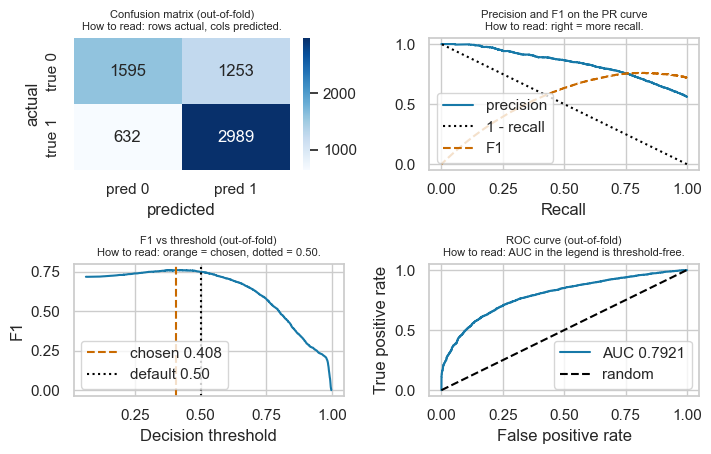


=== Chronological holdout (1294 of 6469 rows), split by whether the customer was already seen ===
                                   group  rows  share_of_holdout  positive_rate  f1_at_0_50  f1_at_chosen_threshold  roc_auc
returning customer (seen before the cut)  1151            0.8895         0.6151      0.7817                  0.8013   0.8150
         new customer (first appearance)   143            0.1105         0.5245      0.6769                  0.7296   0.7675
                        all holdout rows  1294            1.0000         0.6051      0.7727                  0.7945   0.8115

  -> returning customers are scored better, and 95% of the Kaggle file is made of them,
     which is why the grouped number is quoted as a floor and not as the expectation.


In [8]:
# CELL 8 - Assessment: confusion matrix, PR curve, ROC curve, and F1 as a function of threshold.
oof_preds = (oof >= THRESHOLD).astype(int)
cm = confusion_matrix(y, oof_preds)
tn, fp, fn, tp = cm.ravel()

print("=== Out-of-fold assessment at the tuned threshold ===")
print(classification_report(y, oof_preds, target_names=["no repeat (0)", "repeat (1)"]))
print("  confusion matrix : TN={:,}  FP={:,}  FN={:,}  TP={:,}".format(tn, fp, fn, tp))
print("  ROC-AUC (threshold-free) : {:.4f}".format(roc_auc_score(y, oof)))
print("  accuracy                 : {:.4f}   (always-majority baseline {:.4f})".format(
    accuracy_score(y, oof_preds), max(y.mean(), 1 - y.mean())))

precision, recall, thresholds, f1s = f1_curve(y, oof)

fig, axes = plt.subplots(2, 2, figsize=(7.2, 4.7))   # print width: the PDF places this 1:1
# Sequential scale: counts have no meaningful midpoint, so a diverging palette would
# imply one. Diverging red-green is reserved for signed values such as correlations.
sns.heatmap(pd.DataFrame(cm, index=["true 0", "true 1"], columns=["pred 0", "pred 1"]),
            annot=True, fmt="d", cmap="Blues", ax=axes[0, 0])
axes[0, 0].set_title("Confusion matrix (out-of-fold)")
axes[0, 0].set_xlabel("predicted")
axes[0, 0].set_ylabel("actual")

axes[0, 1].plot(recall, precision, color=PLOT_BLUE, label="precision")
axes[0, 1].plot(recall, 1 - recall, color="black", linestyle=":", label="1 - recall")
axes[0, 1].plot(recall[:-1], f1s, color=PLOT_ORANGE, linestyle="--", label="F1")
axes[0, 1].set_xlabel("Recall")
axes[0, 1].set_title("Precision and F1 on the PR curve")
axes[0, 1].legend()

axes[1, 0].plot(thresholds, f1s, color=PLOT_BLUE)
axes[1, 0].axvline(THRESHOLD, color=PLOT_ORANGE, linestyle="--", label="chosen {:.3f}".format(THRESHOLD))
axes[1, 0].axvline(0.5, color="black", linestyle=":", label="default 0.50")
axes[1, 0].set_xlabel("Decision threshold")
axes[1, 0].set_ylabel("F1")
axes[1, 0].set_title("F1 vs threshold (out-of-fold)")
axes[1, 0].legend()

fpr, tpr, _ = roc_curve(y, oof)
axes[1, 1].plot(fpr, tpr, color=PLOT_BLUE, label="AUC {:.4f}".format(roc_auc_score(y, oof)))
axes[1, 1].plot([0, 1], [0, 1], color="black", linestyle="--", label="random")
axes[1, 1].set_xlabel("False positive rate")
axes[1, 1].set_ylabel("True positive rate")
axes[1, 1].set_title("ROC curve (out-of-fold)")
axes[1, 1].legend()
guide(axes[0, 0], "How to read: rows actual, cols predicted.")
guide(axes[0, 1], "How to read: right = more recall.")
guide(axes[1, 0], "How to read: orange = chosen, dotted = 0.50.")
guide(axes[1, 1], "How to read: AUC in the legend is threshold-free.")
plt.tight_layout()
plt.savefig(FIG_DIR / "nb04_assessment.png", dpi=200)
plt.show()

# What the leaderboard population actually looks like. GroupKFold gives every validation customer an
# empty history, so it scores the hardest version of this problem; the test file is the opposite case,
# since {:.0f}% of its rows belong to customers already in train. A chronological fit is the only
# protocol available here where a scored row can have its own past in the fitting part, so the holdout
# is split into returning and new customers to show which part of the score is which.
cut = int(0.8 * len(y))
chrono_model = clone(base_estimator)
chrono_model.fit(X_best[:cut], y[:cut])
chrono_prob = chrono_model.predict_proba(X_best[cut:])[:, 1]
fit_customers = set(groups[:cut])
hold = [i for i in range(cut, len(y))]
returning_in_holdout = [i for i in hold if groups[i] in fit_customers]
new_in_holdout = [i for i in hold if groups[i] not in fit_customers]

holdout_rows = []
for label, idx in [("returning customer (seen before the cut)", returning_in_holdout),
                   ("new customer (first appearance)", new_in_holdout),
                   ("all holdout rows", hold)]:
    if not idx:
        continue
    t = y[idx]
    p = chrono_prob[[k - cut for k in idx]]
    holdout_rows.append({"group": label, "rows": len(idx),
                         "share_of_holdout": round(len(idx) / len(hold), 4),
                         "positive_rate": round(float(np.mean(t)), 4),
                         "f1_at_0_50": round(f1_score(t, (p >= 0.5).astype(int)), 4),
                         "f1_at_chosen_threshold": round(f1_score(t, (p >= THRESHOLD).astype(int)), 4),
                         "roc_auc": round(roc_auc_score(t, p), 4)})
holdout_table = pd.DataFrame(holdout_rows)
print("\n=== Chronological holdout ({} of {} rows), split by whether the customer was already seen ===".format(
    len(hold), len(y)))
print(holdout_table.to_string(index=False))
holdout_table.to_csv(MET_DIR / "holdout_by_customer_type.csv", index=False)
print("\n  -> returning customers are scored better, and {:.0f}% of the Kaggle file is made of them,".format(
    100.0 * sum(returning) / len(test)))
print("     which is why the grouped number is quoted as a floor and not as the expectation.")

### Cell 9 - Submission
**Purpose.** Predict the test set and prove the file is valid before it is used.
**Method.** Predictions at the tuned threshold, checked against the template for columns, row count,
ID order and value domain, plus a threshold sensitivity table.
**Look at.** The implied positive rate at each threshold: this is the number that moves on the
leaderboard if the test population differs from train.

In [9]:
# CELL 9 - Predict the test set and validate the submission contract before saving.
test_probs = final_model.predict_proba(X_test_sets[winner["feature_set"]])[:, 1]
test_preds = (test_probs >= THRESHOLD).astype(int)

submission = pd.DataFrame({"ID": test["ID"].to_numpy(), TARGET: test_preds})
submission.to_csv(DELIV_DIR / SUBMISSION_FILE, index=False)
pd.DataFrame({"ID": test["ID"].to_numpy(), "prob_repeat_90d": test_probs,
              "pred_at_chosen_threshold": test_preds, "pred_at_0_50": (test_probs >= 0.5).astype(int)}
             ).to_csv(MET_DIR / "test_predictions.csv", index=False)

print("=== Submission contract check ===")
print("  file                                : deliverables/{}".format(SUBMISSION_FILE))
print("  columns == sample_submission        :", list(submission.columns) == list(sample_sub.columns))
print("  rows                                : {} (template {})".format(len(submission), len(sample_sub)))
print("  IDs identical to template, in order :", list(submission["ID"]) == list(sample_sub["ID"]))
print("  predictions are 0/1                 :", sorted(submission[TARGET].unique().tolist()) == [0, 1])
print("  nulls                               :", int(submission.isna().sum().sum()))
print("  predicted positive rate             : {:.4f}  (train {:.4f})".format(
    submission[TARGET].mean(), y.mean()))
print("  test probability mean / median      : {:.4f} / {:.4f}".format(
    float(test_probs.mean()), float(np.median(test_probs))))
print("  positive rate at 0.50               : {:.4f}".format(float((test_probs >= 0.5).mean())))
print("  how many predictions the threshold moved vs 0.50: {}".format(
    int((submission[TARGET] != (test_probs >= 0.5).astype(int)).sum())))
print("  A higher positive rate than train is expected: the test rows are later and their")
print("  customers are longer-tenured (NB01/NB02), and the held-out chronological tail above")
print("  already shows a higher positive rate than the earlier rows.")
# Threshold sensitivity: the same thresholds scored on the two kinds of evidence available, and
# the positive rate each one implies for the submission. This is the decision that moves the
# leaderboard number, so it is shown rather than asserted.
sens = pd.DataFrame([{"threshold": t,
                      "oof_f1_grouped": f1_score(y, (oof >= t).astype(int)),
                      "f1_chronological_holdout": f1_score(y[cut:], (p_ch >= t).astype(int)),
                      "implied_test_positive_rate": float((test_probs >= t).mean())}
                     for t in [0.35, 0.40, round(float(THRESHOLD), 4), 0.45, 0.50]])
print("\n=== Threshold sensitivity ===")
print(sens.to_string(index=False, float_format=lambda v: "{:.4f}".format(v)))
print("  F1 is flat between about 0.40 and 0.475 on both protocols, so the choice is not")
print("  knife-edge; 0.50 is measurably worse on both, which is why it is not used.")
sens.to_csv(MET_DIR / "threshold_sensitivity.csv", index=False)

assert list(submission.columns) == list(sample_sub.columns)
assert list(submission["ID"]) == list(sample_sub["ID"])
assert int(submission.isna().sum().sum()) == 0
print("\n  first rows:")
print(submission.head().to_string(index=False))

=== Submission contract check ===
  file                                : deliverables/ML_Group_22_Version01.csv
  columns == sample_submission        : True
  rows                                : 986 (template 986)
  IDs identical to template, in order : True
  predictions are 0/1                 : True
  nulls                               : 0
  predicted positive rate             : 0.7647  (train 0.5597)
  test probability mean / median      : 0.6166 / 0.6353
  positive rate at 0.50               : 0.6542
  how many predictions the threshold moved vs 0.50: 109
  A higher positive rate than train is expected: the test rows are later and their
  customers are longer-tenured (NB01/NB02), and the held-out chronological tail above
  already shows a higher positive rate than the earlier rows.

=== Threshold sensitivity ===
 threshold  oof_f1_grouped  f1_chronological_holdout  implied_test_positive_rate
    0.3500          0.7548                    0.7993                      0.8235
    0

### Cell 10 - Persist and conclude
**Purpose.** Save every metric and state the honest expectation for Kaggle.
**Look at.** The nested F1 and the chronological F1. The chronological one is the realistic figure,
because the test window is later than the training window.

In [10]:
# CELL 10 - Persist the metrics and summarise what Notebook 04 concluded.
def to_native(v):
    if isinstance(v, (np.integer,)):
        return int(v)
    if isinstance(v, (np.floating,)):
        return float(v)
    if v is None or isinstance(v, (bool, int, float, str)):
        return v
    return str(v)


metrics = {
    "model": winner["model"],
    "feature_set": winner["feature_set"],
    "n_features": len(feature_sets[winner["feature_set"]]),
    "best_params": winner["best_params"],
    "cv_f1_groupkfold": to_native(winner["cv_f1_mean"]),
    "oof_f1_at_chosen_threshold": to_native(thr_f1),
    "oof_f1_at_0_50": to_native(f1_score(y, (oof >= 0.5).astype(int))),
    "nested_honest_f1": to_native(nested["f1_at_tuned"].mean()),
    "nested_honest_f1_std": to_native(nested["f1_at_tuned"].std()),
    "chosen_threshold": to_native(THRESHOLD),
    "roc_auc": to_native(roc_auc_score(y, oof)),
    "accuracy": to_native(accuracy_score(y, oof_preds)),
    "always_majority_f1": to_native(2 * y.mean() / (1 + y.mean())),
    "test_positive_rate": to_native(test_preds.mean()),
    "chronological_cv_f1": to_native(prot[prot["protocol"].str.startswith("TimeSeries")]["cv_f1_mean"].tolist()[0]),
    "chronological_holdout_f1": to_native(f1_score(y[cut:], (chrono_prob >= THRESHOLD).astype(int))),
    "holdout_f1_returning_customer": to_native(
        holdout_table[holdout_table["group"].str.startswith("returning")]["f1_at_chosen_threshold"].tolist()[0]),
    "holdout_f1_new_customer": to_native(
        holdout_table[holdout_table["group"].str.startswith("new")]["f1_at_chosen_threshold"].tolist()[0]),
    "test_rows_from_returning_customers": to_native(sum(returning) / len(test)),
    "grouped_val_rows_with_a_known_customer": to_native(float(audit_value("GroupKFold", "share_of_validation_rows"))),
    "random_split_val_rows_with_a_known_customer": to_native(float(audit_value("StratifiedKFold", "share_of_validation_rows"))),
}
with open(MET_DIR / "assessment.json", "w", encoding="utf-8") as fh:
    json.dump(metrics, fh, indent=2)

prot.to_csv(MET_DIR / "validation_protocols.csv", index=False)
full_df.to_csv(MET_DIR / "model_comparison.csv", index=False)
nested.to_csv(MET_DIR / "threshold_nested_cv.csv", index=False)
readout.to_csv(MET_DIR / "model_readout.csv", index=False)
pd.DataFrame({"threshold": thresholds, "f1": f1s}).to_csv(MET_DIR / "f1_by_threshold.csv", index=False)

# The confusion matrix and the out-of-fold probabilities are saved as well, so the summary PDF
# can redraw them as vectors instead of shrinking a screenshot.
pd.DataFrame({"threshold": [THRESHOLD], "tn": [int(tn)], "fp": [int(fp)], "fn": [int(fn)],
              "tp": [int(tp)]}).to_csv(MET_DIR / "confusion_matrix.csv", index=False)
pd.DataFrame({"ID": train["ID"], "customer_id": train["customer_id"], "y_true": y,
              "oof_prob": oof}).to_csv(MET_DIR / "oof_predictions.csv", index=False)

print("=== Notebook 04 summary ===")
for k, v in metrics.items():
    print("  {:32s}: {}".format(k, v))
print("\n  Expected Kaggle F1 (nested, threshold unseen by the evaluated fold) : {:.4f}".format(
    metrics["nested_honest_f1"]))
print("  Expected Kaggle F1 under the chronological protocol                  : {:.4f}".format(
    metrics["chronological_cv_f1"]))
print("  Chronological holdout at the submitted threshold                     : {:.4f}".format(
    metrics["chronological_holdout_f1"]))
print("\n  The two protocols bracket the submission. GroupKFold has never seen the customer before")
print("  (0% of its validation rows are returning customers), while {:.0f}% of the Kaggle rows are,".format(
    100.0 * metrics["test_rows_from_returning_customers"]))
print("  and the holdout shows returning customers are scored at {:.4f} against {:.4f} for new ones.".format(
    metrics["holdout_f1_returning_customer"], metrics["holdout_f1_new_customer"]))
print("  The chronological number is the honest one: the test window is later than train and its")
print("  customers are longer-tenured (NB01/NB02), so it is what the leaderboard will likely see.")

=== Notebook 04 summary ===
  model                           : logistic
  feature_set                     : NB02 all features
  n_features                      : 124
  best_params                     : {'clf__C': 0.03, 'clf__class_weight': None}
  cv_f1_groupkfold                : 0.7484275518221073
  oof_f1_at_chosen_threshold      : 0.7602696171944551
  oof_f1_at_0_50                  : 0.7484801357274141
  nested_honest_f1                : 0.7550270692537511
  nested_honest_f1_std            : 0.012671652234735504
  chosen_threshold                : 0.40768625239932993
  roc_auc                         : 0.7921011833282133
  accuracy                        : 0.7086102952542896
  always_majority_f1              : 0.7177403369672943
  test_positive_rate              : 0.7647058823529411
  chronological_cv_f1             : 0.7413920166677636
  chronological_holdout_f1        : 0.7945041816009558
  holdout_f1_returning_customer   : 0.8013
  holdout_f1_new_customer         : 0.7296
  te

---

## Where this notebook leaves the project

**Produced.** `deliverables/ML_Group_22_Version01.csv` for Kaggle - the exact file the notebook just built, so the selected submission and the documented model cannot disagree. Every metric in
`artifacts/metrics/` (including `test_predictions.csv` with the raw probabilities, so a different
threshold can be applied without retraining), and the four-panel assessment figure in
`artifacts/figures/`.

**What to report on the leaderboard.** The nested, threshold-unseen F1 and the chronological
estimate are both printed in Cell 10. The chronological one is the realistic expectation, because
the test window is later than the training window.

**Final deliverable: the 2-page PDF.** The course asks for a two-page summary named
`Homework_Group22` alongside this notebook. The material is already assembled: the pipeline figure
story is in `artifacts/figures/` (NB01 exploration, NB02 before/after, NB03 funnel and CV
comparison, NB04 assessment), the numbers are in `artifacts/metrics/assessment.json`, and the
auditable decisions are in the two logs under `artifacts/logs/`.

**Reproducing everything from a clean clone.** Create the environment from `environment.yml` or
`requirements.txt`, put the four supplied CSVs in `data/`, then run the notebooks in order.
No step needs a pickle file, no folder is created by code, and no step reads test data to fit anything.